# Boston 311 ingestion

Load the 2023 and 2024 Boston 311 files into a local LanceDB database. The CSVs and the database share `./data`.

Four tables come out of this:

- `requests`: one row per in-scope request, cleaned, no vectors. Used for forecasting and staffing.
- `request_types`: one row per distinct request type, embedded by LanceDB. Used by the intake assistant to match a resident message to a type, department and queue.
- `type_aliases`: LLM-written resident phrasings for each type. Cached, so reruns do not call the LLM again.
- `intake_eval`: synthetic resident messages with the right answer, for measuring search accuracy.

Scope and gotchas come from `https://www.ai2lab.ai/courses/DADS5250/hackathon/#p2`. 

Only the four departments in scope are kept: Public Works (PWDx), Transportation (BTDT), Parks (PARK) and Inspectional Services (ISD).

In [6]:
import html
from pathlib import Path

import lancedb
import numpy as np
import pandas as pd
from lancedb.index import FTS
from lancedb.pydantic import LanceModel, Vector

from core.llm import MODEL, parse
from core.models import AliasBatch, EvalBatch
from db.request_types import DATA, embedder

BASE = "https://data.boston.gov/dataset/8048697b-ad64-4bfc-b090-ee00169f2323/resource"
FILES = {
    "lagan_311_open_data_2023_rvsd3.csv": f"{BASE}/e6013a93-1321-4f2a-bf91-8d8a02f1e62f/download/lagan_311_open_data_2023_rvsd3.csv",
    "lagan_311_open_data_2024_rvsd3.csv": f"{BASE}/dff4d804-5031-443a-8409-8344efd0e5c8/download/lagan_311_open_data_2024_rvsd3.csv",
}
DEPARTMENTS = {
    "PWDx": "Public Works",
    "BTDT": "Transportation",
    "PARK": "Parks and Recreation",
    "ISD": "Inspectional Services",
}

DATA.mkdir(exist_ok=True)
db = lancedb.connect(DATA / "lancedb")


## Download

Files are cached in `./data`. A file that already exists is not fetched again. Each is about 180 MB.

In [7]:
for name, url in FILES.items():
    path = DATA / name
    if not path.exists():
        tmp = path.with_suffix(".part")
        urllib.request.urlretrieve(url, tmp)
        tmp.rename(path)
    print(f"{name}: {path.stat().st_size / 1e6:.0f} MB")


lagan_311_open_data_2023_rvsd3.csv: 184 MB
lagan_311_open_data_2024_rvsd3.csv: 182 MB


## Load and clean

Gotchas handled here:

- Keep only the four departments.
- Text has HTML codes like `&amp;`, so decode them. Underscores in type names (`Mattress_Pickup`) become spaces.
- About 16% of requests have no `sla_target_dt` overall. In scope it is mostly Public Works. The nulls stay null and `has_sla` flags them.
- Some target dates are very long (Parks uses 365 days), so `sla_days` is kept for filtering later.
- 42% of 2024 requests are `Employee Generated`, so `is_employee` is kept for the resident vs employee split.
- Timestamps are Boston local time. They are stored without a timezone.
- `open_month` is added so monthly counts are one group-by away.

In [8]:
COLUMNS = [
    "case_enquiry_id", "open_dt", "sla_target_dt", "closed_dt", "on_time", "case_status",
    "case_title", "subject", "reason", "type", "queue", "department", "neighborhood", "source",
]
TEXT = ["case_title", "subject", "reason", "type", "queue", "neighborhood"]
DATES = ["open_dt", "sla_target_dt", "closed_dt"]


def clean_text(s: pd.Series) -> pd.Series:
    return s.map(lambda v: html.unescape(v) if isinstance(v, str) else v).str.replace("_", " ").str.strip()


def load(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, usecols=COLUMNS, dtype=str)
    df = df[df.department.isin(DEPARTMENTS)].copy()
    df[DATES] = df[DATES].apply(pd.to_datetime, format="ISO8601")
    df[TEXT] = df[TEXT].apply(clean_text)
    df["case_enquiry_id"] = df.case_enquiry_id.astype("int64")
    df["open_month"] = df.open_dt.dt.to_period("M").dt.to_timestamp()
    df["has_sla"] = df.sla_target_dt.notna()
    df["sla_days"] = (df.sla_target_dt - df.open_dt).dt.total_seconds() / 86400
    df["days_to_close"] = (df.closed_dt - df.open_dt).dt.total_seconds() / 86400
    df["is_on_time"] = df.on_time.eq("ONTIME")
    df["is_employee"] = df.source.eq("Employee Generated")
    return df


requests = pd.concat([load(DATA / name) for name in FILES], ignore_index=True)
requests = requests.drop_duplicates("case_enquiry_id")
print(f"{len(requests):,} in-scope requests")
requests.groupby([requests.open_dt.dt.year.rename("year"), "department"]).size().unstack()


558,663 in-scope requests


department,BTDT,ISD,PARK,PWDx
year,,,,
2023,75314,18123,17541,171268
2024,81447,18624,18736,157610


The 2024 row counts match the hackathon brief: 157,610 / 81,447 / 18,736 / 18,624.

## Case titles

`case_title` has thousands of variants, but every row also has a `type` from the department. Check how concentrated the titles are, and whether they carry anything the type does not.

In [9]:
def mode(s: pd.Series) -> str:
    return s.value_counts().index[0]


titles = requests.groupby("case_title").size().sort_values(ascending=False)
print(f"{len(titles):,} distinct titles for {requests.type.nunique()} types")
print(f"top 50 titles cover {titles.iloc[:50].sum() / titles.sum():.0%} of rows; {(titles == 1).mean():.0%} of titles appear once")
requests.case_title[~requests.case_title.isin(titles.index[:300])].drop_duplicates().sample(8, random_state=1).tolist()


7,431 distinct titles for 163 types
top 50 titles cover 89% of rows; 66% of titles appear once


['SCH 10/22 Chronic Dampness/Mold',
 'SCH3/3Unsatisfactory Living Conditions',
 'Planting: Doherty Playground - BPRD',
 'Tree In Park: Billings Field; West Roxbury',
 'Street Light Knock Downs//NOTIFIED LIGHTING INSPECTOR',
 'SCH6/16Maintenance Complaint - Residential',
 'Street Light Outages//gas printed for 2nd shift//',
 'PRINTED  //  General Lighting Reques  //  N.M.']

Rare titles are a real title with noise around it: scheduling codes in front (`SCH5/12`), work order notes (`PRINTED : replace twin arm`), place names after a colon. Instead of writing rules to strip that, let embeddings absorb it.

Hold out 20% of rows. Embed the distinct training titles, then give each held-out title the type of its nearest neighbor.

In [10]:
class TitleRow(LanceModel):
    text: str = embedder.SourceField()
    vector: Vector(embedder.ndims()) = embedder.VectorField()
    type: str


shuffled = requests.sample(frac=1, random_state=0)
cut = int(len(shuffled) * 0.8)
train, test = shuffled.iloc[:cut], shuffled.iloc[cut:]
known = train.groupby("case_title").type.agg(mode).reset_index().rename(columns={"case_title": "text"})
neighbors = db.create_table("title_neighbors", schema=TitleRow, data=known, mode="overwrite")
distinct = test.case_title.drop_duplicates()
vectors = embedder.compute_source_embeddings(distinct.tolist())
nearest = pd.Series([neighbors.search(v).limit(1).to_pandas().type[0] for v in vectors], index=distinct)
db.drop_table("title_neighbors")
print(f"{(test.case_title.map(nearest) == test.type).mean():.4f} of held-out rows get the right type from their nearest title")


0.9959 of held-out rows get the right type from their nearest title


The nearest title predicts the department's own type for about 99.6% of held-out rows, with no cleaning rules. The `type` column is already the clean grouping, so titles are only used below as examples when describing a type.

Titles are the city's wording, not the resident's. Matching resident messages directly against titles found the right type first only 28% of the time on the test messages below, so resident phrasing is added separately.

## Write the requests table

The table is rebuilt on every run, so re-running the notebook is safe.

In [11]:
db.create_table("requests", requests, mode="overwrite")
db.open_table("requests").count_rows()


558663

## Embedding function

- Model: `BAAI/bge-small-en-v1.5`. It is 384 dimensions, about 67 MB, and runs as ONNX on CPU through `fastembed`.
- `db/request_types.py` registers a `fastembed` function (LanceDB has no built-in one).
- The intake agent imports the same module to search and LanceDB conveniently embeds the source column on write and embeds the query text on search. 
- Similar to embedding requests, queries get the BGE instruction prefix.

## Request types

- One row per type. The same type is sometimes filed under several departments (Request for Pothole Repair appears under Transportation, Parks and Inspectional Services with a few dozen rows, against 16,927 in Public Works). 
- Each type is kept under the department that handles most of its requests. `queue` is the most common queue for that row, and `n_requests` is its volume over 2023 and 2024.
- The embedded text is the type, reason and subject plus the department name, then the resident phrasings from the next section. The queue is a routing code, so it stays out of the text.

In [12]:
types = (
    requests.groupby(["department", "type", "reason", "subject"], as_index=False)
    .agg(queue=("queue", mode), n_requests=("case_enquiry_id", "size"))
    .sort_values("n_requests", ascending=False)
    .drop_duplicates("type")
    .reset_index(drop=True)
)
types["department_name"] = types.department.map(DEPARTMENTS)
types["text_plain"] = types.type + ". " + types.reason + ". " + types.subject + ". " + types.department_name
print(f"{len(types)} request types")
types.head(3)[["department", "type", "queue", "n_requests"]]


163 request types


,department,type,queue,n_requests
0,BTDT,Parking Enforcement,BTDT Parking Enforcement,119597
1,PWDx,Requests for Street Cleaning,PWDx District 1C: Downtown,39681
2,PWDx,Improper Storage of Trash (Barrels),PWDx Code Enforcement,39541


Median days to close and on-time rate are per type, over 2024 requests only. Open requests have no close date and drop out of the median.

In [13]:
stats_2024 = (
    requests[requests.open_dt.dt.year == 2024]
    .groupby("type")
    .agg(median_days_to_close=("days_to_close", "median"), on_time_rate_2024=("is_on_time", "mean"))
)
types = types.merge(stats_2024, on="type", how="left")


## Resident phrasing

- Type names are agency labels ("CE Collection", "BWSC Pothole") but residents do not write like that. 
- An LLM writes a few everyday phrasings per type, grounded in the type's most common case titles, and those get embedded with the type text.
- Calls go through `core.llm` with Pydantic models from `core.models`, in batches of 20 types. 
- Results are cached in the `type_aliases` table, so only types without aliases are sent.

In [14]:
ALIAS_PROMPT = """You help a Boston 311 intake assistant match what residents write to city request types.
For each numbered request type, write 6 short phrases a resident might use to report that problem in everyday words.
Use plain language, no department jargon, and do not repeat the type name. The example titles show what the type covers."""

types["resident_share"] = types.type.map(1 - requests.groupby("type").is_employee.mean())
types["examples"] = types.type.map(requests.groupby("type").case_title.agg(lambda s: "; ".join(s.value_counts().index[:3])))


def table_names() -> list[str]:
    return db.list_tables().tables


def generate_aliases(todo: pd.DataFrame) -> None:
    for start in range(0, len(todo), 20):
        batch = todo.iloc[start:start + 20]
        prompt = "\n".join(f"{i}. {r['type']} | {r['reason']} | {r['subject']} | {r['department_name']} | example titles: {r['examples']}" for i, r in batch.iterrows())
        found = {a.type_id: a.aliases for a in parse(AliasBatch, ALIAS_PROMPT, prompt).items if a.type_id in batch.index}
        rows = [{"type": batch.type[i], "aliases": aliases} for i, aliases in found.items()]
        if "type_aliases" in table_names():
            db.open_table("type_aliases").add(rows)
        else:
            db.create_table("type_aliases", rows)


done = set(db.open_table("type_aliases").to_pandas().type) if "type_aliases" in table_names() else set()
generate_aliases(types[~types.type.isin(done)])
aliases = db.open_table("type_aliases").to_pandas().set_index("type").aliases
extra = types.type.map(lambda t: "; ".join(aliases.get(t, [])))
types["text"] = types.text_plain + (". Also reported as: " + extra).where(extra != "", "")
print(f"{MODEL}: {types.type.isin(aliases.index).sum()} of {len(types)} types have aliases")
types.sample(3, random_state=0).text.tolist()


openai/gpt-4o-mini: 163 of 163 types have aliases


["Undefined Noise Disturbance. Generic Noise Disturbance. Mayor's 24 Hour Hotline. Inspectional Services. Also reported as: There's a loud noise outside; I can't sleep because of noise; Someone's making a lot of noise at night; There's a disruptive sound in my area; I hear loud music all the time; Can someone check out this noise?",
 "Scale Not Visible. Weights and Measures. Inspectional Services. Inspectional Services. Also reported as: Can't see the scale; The scale is blocked; Scale isn’t visible to see; Need to fix the visible scale; Visibility issue with the scale; Can't read the scale at all",
 "Food Alert - Unconfirmed. Health. Inspectional Services. Inspectional Services. Also reported as: There's a food safety issue here.; I think this place is unsanitary.; Can you check the restaurant for health issues?; There's a potential health risk with food.; I’m concerned about food safety here.; Please investigate this food establishment."]

## Synthetic test messages

- 40 types are sampled, weighted by the square root of their volume. 
- Only types that residents actually file (at least 20% non-employee requests, at least 100 requests) are eligible. 
- The LLM writes one message per type from the type name only, never from the aliases or titles. 
- Messages are cached in the `intake_eval` table.

In [15]:
EVAL_PROMPT = """You write test messages for a Boston 311 intake assistant. For each numbered request type, write one message a real resident might send to report that problem.
Vary the style: some short and vague, some with a street name or landmark, some with typos or frustration. Never copy the wording of the request type or reason."""

if "intake_eval" not in table_names():
    pool = types[(types.resident_share >= 0.2) & (types.n_requests >= 100)]
    weights = pool.n_requests ** 0.5
    sample = pool.loc[np.random.default_rng(0).choice(pool.index, 40, replace=False, p=weights / weights.sum())]
    rows = []
    for start in range(0, len(sample), 20):
        batch = sample.iloc[start:start + 20]
        prompt = "\n".join(f"{i}. {r['type']} | {r['reason']} | {r['department_name']}" for i, r in batch.iterrows())
        for m in parse(EvalBatch, EVAL_PROMPT, prompt).items:
            if m.type_id in batch.index:
                row = batch.loc[m.type_id]
                rows.append({"message": m.message, "type": row["type"], "department": row.department, "queue": row.queue})
    db.create_table("intake_eval", rows)

eval_set = db.open_table("intake_eval").to_pandas()
print(f"{len(eval_set)} test messages")
eval_set.sample(6, random_state=0)[["message", "type"]]


40 test messages


,message,type
22,The sidewalks are still not shoveled on Beacon...,Unshoveled Sidewalk
20,Can someone come look at the leaky pipe in my ...,Plumbing
25,I’ve seen way too many rats around my trash bi...,Rodent Activity
4,There are vendors everywhere by the T station ...,Illegal Vending
10,There’s a huge pothole on Huntington Avenue th...,Roadway Repair
15,Some neighbors are leaving trash barrels out a...,Improper Storage of Trash (Barrels)


In [16]:
TYPE_COLUMNS = ["text", "department", "department_name", "queue", "type", "reason", "subject", "n_requests", "median_days_to_close", "on_time_rate_2024"]


class RequestType(LanceModel):
    text: str = embedder.SourceField()
    vector: Vector(embedder.ndims()) = embedder.VectorField()
    department: str
    department_name: str
    queue: str
    type: str
    reason: str
    subject: str
    n_requests: int
    median_days_to_close: float | None = None
    on_time_rate_2024: float | None = None

tbl = db.create_table("request_types", schema=RequestType, mode="overwrite", data=types[TYPE_COLUMNS])
tbl.create_index("text", config=FTS(), replace=True)
tbl.count_rows()


163

## Accuracy on synthetic messages

For each message, search the index and see where the right type lands. The same run on an index built without aliases shows what the aliases add.

The messages come from the same LLM that wrote the aliases, so the scores are optimistic. Hand-written messages are the honest test.

In [17]:
def evaluate(table, k: int = 5) -> pd.Series:
    ranks, dept_hits = [], []
    for message, truth, dept in zip(eval_set.message, eval_set.type, eval_set.department):
        hits = table.search(message, query_type="hybrid").limit(k).to_pandas()
        found = hits.type.tolist()
        ranks.append(found.index(truth) + 1 if truth in found else None)
        dept_hits.append(hits.department.iloc[0] == dept)
    r = pd.Series(ranks, dtype="float")
    return pd.Series({"type_top1": (r == 1).mean(), "type_top3": (r <= 3).mean(), "type_top5": r.notna().mean(), "department_top1": sum(dept_hits) / len(dept_hits)})


plain = db.create_table("request_types_plain", schema=RequestType, mode="overwrite", data=types[TYPE_COLUMNS].assign(text=types.text_plain))
plain.create_index("text", config=FTS(), replace=True)
comparison = pd.DataFrame({"without aliases": evaluate(plain), "with aliases": evaluate(tbl)}).round(3)
db.drop_table("request_types_plain")
comparison


,without aliases,with aliases
type_top1,0.500,0.525
type_top3,0.675,0.775
type_top5,0.750,0.800
department_top1,0.925,0.900


## Search

`tbl.search(text)` embeds the query with the same function and runs vector search. `query_type="hybrid"` adds full text search on the same column. Sample messages in the spirit of the hackathon brief:

In [18]:
MESSAGES = [
    "there's a big hole on Centre St near the T stop",
    "someone parked across my driveway again",
    "the streetlight on my corner has been out for a week",
    "rats behind the restaurant on Washington St",
    "overflowing trash barrels outside the apartment next door",
    "dead tree limb hanging over the playground",
    "landlord won't fix the heat",
]
for msg in MESSAGES:
    hits = tbl.search(msg, query_type="hybrid").limit(3).to_pandas()
    print(msg)
    for r in hits.itertuples():
        print(f"    {r.department:5} {r.queue:40} {r.type}")


there's a big hole on Centre St near the T stop
    PWDx  PWDx Contractor Complaints               Request for Pothole Repair
    PWDx  PWDx Highway Construction                Sidewalk Cover / Manhole
    PWDx  PWDx Contractor Complaints               BWSC Pothole
someone parked across my driveway again
    PWDx  PWDx Code Enforcement                    Parking on Front/Back Yards (Illegal Parking)
    PARK  PARK Maintenance Lighting Electrical     Parks Lighting/Electrical Issues
    BTDT  BTDT Parking Lot PrivateParkingLotComplaints Private Parking Lot Complaints
the streetlight on my corner has been out for a week
    PWDx  PWDx Highway Construction General        StreetLight Pole WO
    PWDx  PWDx Street Light Outages                Street Light Outages
    PWDx  PWDx Street Light Upgrade Existing Lighting Upgrade Existing Lighting
rats behind the restaurant on Washington St
    ISD   ISD Health (INTERNAL)                    Fire in Food Establishment
    ISD   ISD Environmental S

## Check

The database folder should hold the four tables, and 2024 counts should match the brief.

In [19]:
brief_2024 = {"PWDx": 157610, "BTDT": 81447, "PARK": 18736, "ISD": 18624}
counts = db.open_table("requests").to_pandas()
counts = counts[counts.open_dt.dt.year == 2024].department.value_counts().to_dict()
assert counts == brief_2024, counts
print(db.list_tables().tables, counts)
db.open_table("request_types").to_pandas()[["type", "median_days_to_close", "on_time_rate_2024"]].head()


['intake_eval', 'request_types', 'requests', 'type_aliases'] {'PWDx': 157610, 'BTDT': 81447, 'PARK': 18736, 'ISD': 18624}


,type,median_days_to_close,on_time_rate_2024
0,Parking Enforcement,0.700023,0.482113
1,Requests for Street Cleaning,0.093271,0.965425
2,Improper Storage of Trash (Barrels),0.120141,0.997394
3,Mattress Pickup,2.953076,1.000000
4,CE Collection,0.068883,0.993393


## TEST Department and Type Retreival from Messages passed to LLM

Using "Message" input from ./eval/intake_test_set.csv which contains a message along with expected_department and expected_type, run "messages" from test set through the LLM and retreive predicted departement and type values.

Results are stored in ./eval/intake_test_results.csv

In [ ]:
#load message from intake_test_set.csv into testPD
testPD = pd.read_csv(
    Path("eval") / "intake_test_set.csv",
    encoding="cp1252",
)

#perform search using only message column from testPD
results = []
for msg in testPD["message"].tolist():
    hits = tbl.search(msg, query_type="hybrid").limit(1).to_pandas()
    # print(msg)
    if hits.empty:
        results.append({"initial_message": msg, "department": None, "type": None})
        continue

    result = hits.iloc[0]
    results.append(
        {
            "initial_message": msg,
            "department": result["department"],
            "type": result["type"],
        }
    )

resultsPD = pd.DataFrame(results, columns=["initial_message", "department", "type"])

# append expected_department and expected_type columns from testPD to resultsPD
resultsPD = resultsPD.merge(
    testPD[["message", "expected_department", "expected_type"]],
    left_on="initial_message",
    right_on="message",
    how="left",
).drop(columns=["message"])

#save resultsPD to intake_test_results.csv in eval folder
resultsPD.to_csv(
    Path("eval") / "intake_test_results.csv",
    index=False,
    encoding="cp1252",
)

print(f"Results saved to {Path('eval') / 'intake_test_results.csv'}")



Results saved to eval\intake_test_results.csv


## Test Results Precision / Recall / Accuracy (Department | Type)

Evaluating test results from a concrete test ./eval/intake_test_results.csv
this compares expected types and expected values from retrieved messages versus the actual type and actual value results

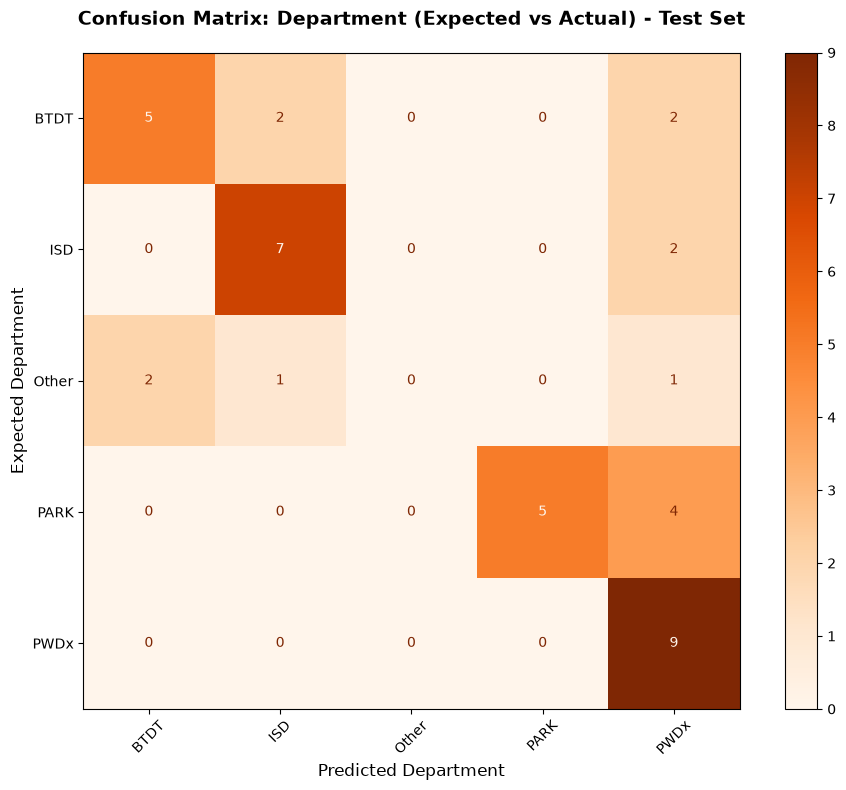

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Load the results file
file_path = Path("eval") / "intake_test_results.csv"
df = pd.read_csv(file_path, encoding="cp1252")

df['expected_department'] = df['expected_department'].fillna('Unknown').astype(str).str.strip()
df['department'] = df['department'].fillna('Unknown').astype(str).str.strip()

# 3. Pull unified labels so axes match perfectly
type_labels = sorted(list(set(df['expected_type']).union(set(df['type']))))
dept_labels = sorted(list(set(df['expected_department']).union(set(df['department']))))

# =====================================================================
# MATRIX: Department (Expected vs Actual)
# =====================================================================
cm_dept = confusion_matrix(df['expected_department'], df['department'], labels=dept_labels)

fig, ax = plt.subplots(figsize=(10, 8))
disp_dept = ConfusionMatrixDisplay(confusion_matrix=cm_dept, display_labels=dept_labels)
disp_dept.plot(cmap=plt.cm.Oranges, ax=ax, xticks_rotation=45, values_format='d')

plt.title("Confusion Matrix: Department (Expected vs Actual) - Test Set", fontsize=14, fontweight='bold', pad=20)
plt.xlabel("Predicted Department", fontsize=12)
plt.ylabel("Expected Department", fontsize=12)
plt.tight_layout()
plt.show()

In [76]:
from sklearn.metrics import precision_score, recall_score

# precision accuracy and recall for department

precision_dept = precision_score(
    df["expected_department"],
    df["department"],
    average="macro",
    labels=dept_labels,
    zero_division=0,
)
recall_dept = recall_score(
    df["expected_department"],
    df["department"],
    average="macro",
    labels=dept_labels,
    zero_division=0
)
accuracy_dept = (df["expected_department"] == df["department"]).mean()
f1_dept = 2 * (precision_dept * recall_dept) / (precision_dept + recall_dept) if (precision_dept + recall_dept) > 0 else 0

#print Test Set Evaluation Metrics for Department and Type
print("Test Set Evaluation Metrics for Department and Type:")
print(f"Precision (Department): {precision_dept:.2f}")
print(f"Recall (Department): {recall_dept:.2f}")
print(f"Accuracy (Department): {accuracy_dept:.2f}")
print(f"F1 Score (Department): {f1_dept:.2f}")

# precision accuracy and recall for type
precision_type = precision_score(
    df["expected_type"],
    df["type"],
    average="macro",
    zero_division=0
)
recall_type = recall_score(
    df["expected_type"],
    df["type"],
    average="macro",
    zero_division=0
)
accuracy_type = (df["expected_type"] == df["type"]).mean()
f1_type = 2 * (precision_type * recall_type) / (precision_type + recall_type) if (precision_type + recall_type) > 0 else 0

print(f"Precision (Type): {precision_type:.2f}")
print(f"Recall (Type): {recall_type:.2f}")
print(f"Accuracy (Type): {accuracy_type:.2f}")
print(f"F1 Score (Type): {f1_type:.2f}")

Test Set Evaluation Metrics for Department and Type:
Precision (Department): 0.58
Recall (Department): 0.58
Accuracy (Department): 0.65
F1 Score (Department): 0.58
Precision (Type): 0.21
Recall (Type): 0.20
Accuracy (Type): 0.30
F1 Score (Type): 0.20


## Demo Application

- Use Jupyter Magic `%load_ext gradio` to support hotloading
- Supports changes to agent/demo code that can be previewed without restarting Jupyter
- To reload App, simply execute the cell with `%%blocks` magic

In [ ]:
# %load_ext gradio


In [21]:
# %%blocks
# import importlib

# import agents.intake.agent as agent
# import ui.gradio_app as app

# for module in (agent, app):
#     importlib.reload(module)
# demo = app.demo
